In [1]:
import math
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# matplot 에서 한글을 표시하기 위한 설정
from matplotlib import font_manager, rc
font_name  = font_manager.FontProperties(fname="c:/Windows/Fonts/malgun.ttf").get_name()
rc('font', family=font_name)

# 단어 벡터를 분석해볼 임의의 문장들
sentences = ["나 고양이 좋다",
             "나 강아지 좋다",
             "나 동물 좋다",
             "강아지 고양이 동물",
             "여자친구 고양이 강아지 좋다",
             "고양이 생선 우유 좋다",
             "강아지 생선 싫다 우유 좋다",
             "강아지 고양이 눈 좋다",
             "나 여자친구 좋다",
             "여자친구 나 싫다",
             "여자친구 나 영화 책 음악 좋다",
             "나 게임 만화 애니 좋다",
             "고양이 강아지 싫다",
             "강아지 고양이 좋다"]

# 문장을 전부 합친 후 공백으로 단어들을 나누고 고유한 단어들로 리스트를 만듬니다.
word_list = " ".join(sentences).split()
word_list = list(set(word_list))

# 문자열로 분석하는 것 보다, 숫자로 분석하는 것이 훨씬 용이하므로
# 리스트에서 문자들의 인덱스를 뽑아서 사용하기 위해,
# 이를 표현하기 위한 연관 배열과, 단어 리스트에서 단어를 참조 할 수 있는 인덱스 배열을 만듭니다.
word_dict = {w: i for i, w in enumerate(word_list)}
word_index = [word_dict[word] for word in word_list]

# 윈도우 사이즈를 1 로 하는 skip-gram 모델을 만듭니다.
# 예) 나 게임 만화 애니 좋다
#   -> ([나, 만화], 게임), ([게임, 애니], 만화), ([만화, 좋다], 애니)
#   -> (게임, 나), (게임, 만화), (만화, 게임), (만화, 애니), (애니, 만화), (애니, 좋다)
skip_grams = []

for i in range(1, len(word_index) - 1):
    # (context, target) : ([target index - 1, target index + 1], target)
    target = word_index[i]
    context = [word_index[i - 1], word_index[i + 1]]
    
    # (target, context[0]), (target, context[1])..
    for w in context:
        skip_grams.append([target, w])

In [2]:
# skip-gram 데이터에서 무작위로 데이터를 뽑아 입력값과 출력값의 배치 데이터를 생성하는 함수
def random_batch(data, size):
    random_inputs = []
    random_labels = []
    random_index = np.random.choice(range(len(data)), size, replace = False)
    
    for i in random_index:
        random_inputs.append(data[i][0]) # target
        random_labels.append([data[i][1]]) # context word
    
    return random_inputs, random_labels

In [3]:
# 러닝 옵션 설정

# 한 번에 학습할 데이터의 크기
batch_size = 20

# 단어 벡터를 구성할 임베딩 차원의 크기
# 이 예제에서는 x, y 그래프로 표현하기 쉽게 2 개의 값만 출력하도록 합니다.
embedding_size = 2

# word2vec 모델을 학습시키기 위한 nce_loss 함수에서 사용하기 위한 샘플링 크기
# batch_size 보다 작아야 합니다.
num_sampled = 15

# 총 단어 갯수
vocabulary_size = len(word_list)

In [4]:
# 모델 빌드

# 입력 - target
train_inputs = tf.placeholder(tf.int32, shape = [batch_size])

# 라벨 - context word
# tf.nn.nce_loss 를 사용하려면 출력값을 이렇게 [batch_size, 1] 구성해야합니다.
train_labels = tf.placeholder(tf.int32, shape = [batch_size, 1])

# word2vec 모델의 결과 값인 임베딩 벡터를 저장할 변수입니다.
# 총 단어 갯수와 임베딩 갯수를 크기로 하는 두 개의 차원을 갖습니다.
embeddings = tf.Variable(tf.random_uniform([vocabulary_size, embedding_size], -1.0, 1.0))

# 가중치(weights)와 편향(biases) 을 정의
nce_weights = tf.Variable(
    tf.truncated_normal([vocabulary_size, embedding_size], 
                        stddev = 1.0 / math.sqrt(embedding_size)))
nce_biases = tf.Variable(tf.zeros([vocabulary_size]))

# 임베딩 벡터의 차원에서 학습할 입력값에 대한 행들을 뽑아옵니다.
# 예) embeddings     inputs    selected
#    [[1, 2, 3]  -> [2, 3] -> [[2, 3, 4]
#     [2, 3, 4]                [3, 4, 5]]
#     [3, 4, 5]
#     [4, 5, 6]]
embed = tf.nn.embedding_lookup(embeddings, train_inputs)

# NCD loss
loss = tf.reduce_mean(
    tf.nn.nce_loss(nce_weights, nce_biases, embed, train_labels, 
                   num_sampled, vocabulary_size))

# SGD optimizer
optimizer = tf.train.GradientDescentOptimizer(learning_rate = 1.0).minimize(loss)

In [5]:
# Learning

init = tf.global_variables_initializer()

with tf.Session() as sess:
    init.run()
    print("Initialized")
    
    average_loss = 0
    for step in range(301):
        batch_inputs, batch_labels = random_batch(skip_grams, batch_size)
        feed_dict = {train_inputs: batch_inputs, train_labels: batch_labels}
        
        # We perform one update step by evaluating the optimizer op (including it
        # in the list of returned values for session.run()
        _, loss_val = sess.run([optimizer, loss], feed_dict = feed_dict)
        average_loss += loss_val
        
        if step % 10 == 0:
            if step > 0:
                average_loss /= 10
            print("loss at step ", step, ": ", average_loss)
            average_loss = 0
    
    # matplot 으로 출력하여 시각적으로 확인해보기 위해
    # 임베딩 벡터의 결과 값을 계산하여 저장합니다.
    trained_embeddings = embeddings.eval()

Initialized
loss at step  0 :  12.1054935455
loss at step  10 :  5.30608658791
loss at step  20 :  3.69379928112
loss at step  30 :  3.49248285294
loss at step  40 :  3.37789993286
loss at step  50 :  3.25293989182
loss at step  60 :  3.16379563808
loss at step  70 :  3.05364792347
loss at step  80 :  3.02699885368
loss at step  90 :  2.92823393345
loss at step  100 :  2.88857066631
loss at step  110 :  2.8646399498
loss at step  120 :  2.80261361599
loss at step  130 :  2.78098268509
loss at step  140 :  2.73445858955
loss at step  150 :  2.72367773056
loss at step  160 :  2.71260561943
loss at step  170 :  2.68091013432
loss at step  180 :  2.64474885464
loss at step  190 :  2.63800151348
loss at step  200 :  2.62511491776
loss at step  210 :  2.62240068913
loss at step  220 :  2.6066108942
loss at step  230 :  2.59634401798
loss at step  240 :  2.57560119629
loss at step  250 :  2.56244170666
loss at step  260 :  2.56088962555
loss at step  270 :  2.55501189232
loss at step  280 :  

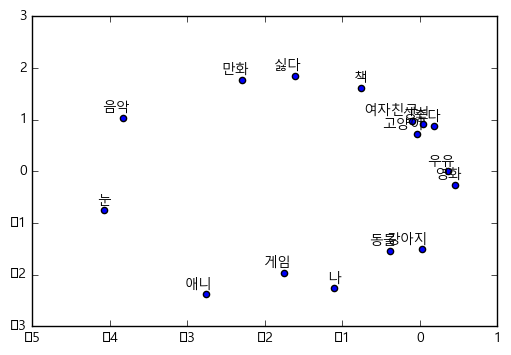

In [6]:
# Result
for i, label in enumerate(word_list):
    x, y = trained_embeddings[i]
    
    plt.scatter(x, y)
    plt.annotate(label, xy = (x, y), xytext = (5, 2),
                textcoords = 'offset points', ha = 'right', va = 'bottom')

plt.show()